# **LABWORK 1: Principle component analysis**

## **I. Study the dataset**

In [2]:
%pip install pandas

from pathlib import Path
import pandas as pd

data_dir = Path("data")

csv_files = sorted(data_dir.glob("*.csv"))

print("No. CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
No. CSV files: 9
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [3]:
tables = {
    file.stem: pd.read_csv(file)
    for file in csv_files
}

In [4]:
overview = pd.DataFrame([
    {
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    }
    for name, df in tables.items()
])

display(overview)

,table,rows,columns
0,olist_customers_dataset,99441,5
1,olist_geolocation_dataset,1000163,5
2,olist_order_items_dataset,112650,7
3,olist_order_payments_dataset,103886,5
4,olist_order_reviews_dataset,99224,7
5,olist_orders_dataset,99441,8
6,olist_products_dataset,32951,9
7,olist_sellers_dataset,3095,4
8,product_category_name_translation,71,2


In [5]:
for name, df in tables.items():
    print(f"\n{name}")
    print(df.columns.tolist())


olist_customers_dataset
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

olist_geolocation_dataset
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

olist_order_items_dataset
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

olist_order_payments_dataset
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

olist_order_reviews_dataset
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

olist_orders_dataset
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

olist_products_dataset
['product_id', 'product_category_name', 'product_name_lenght', 'product_

### **1. Choose dataset satisfying requirements**

In [6]:
products = tables["olist_products_dataset"].copy()

print("Number of products:", products.shape[0])
print("Number of columns:", products.shape[1])

display(products.head())

products.info()

Number of products: 32951
Number of columns: 9


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


### **2. Identify Feature Types**

| Feature | Quantitative or Qualitative | Numerical or Categorical | Discrete or Continuous |
|---|---|---|---|
| `product_id`, `product_category_name` | Qualitative | Categorical | |
| `product_name_lenght`, `product_description_lenght`, `product_photos_qty` | Quantitative | Numerical | Discrete |
| `product_weight_g`, `product_length_cm`, `product_height_cm`, `product_width_cm` | Quantitative | Numerical | Continuous |

**Quantitative - Qualitative:**
| Type | Meaning | eg |
|---|---|---|
| **Quantitative** |a quantity that can be counted, or measured | no. photos, weight, height (eg: wieght = 500g) |
| **Qualitative** | a characteristic, category, identity | color, product category, product ID (eg: category = electronics) |

**Numerical - Categorical:**
| Type | Meaning | Examples | Notation |
|---|---|---|---|
| **Numerical** | Values represent quantities; calculations such as differences or averages are meaningful | Price, weight, number of photos | Quantitative → Numerical | 
| **Categorical** | Values identify groups or objects | Product category, postal code, product ID | Qualitative → Categorical |

**Discrete - Continuous:**
| Type | Meaning | Examples |
|---|---|---|
| **Discrete** | Takes separate, distinct values; usually obtained by counting | Number of photos: 1, 2, 3… |
| **Continuous** | Can theoretically take any value within a range; usually obtained by measuring | Weight: 500 g, 500.2 g, 500.25 g… |

### **3. Identify missing values, duplicate records, incorrect values, inconsistencies, outliers**

**Check for missing values**

In [7]:
missing_summary = pd.DataFrame({
    "missing_count": products.isna().sum(),
    "missing_percent": products.isna().mean() * 100
})

display(missing_summary.round(2))

,missing_count,missing_percent
product_id,0,0.00
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


**Check for duplicate data**

In [8]:
print("Duplicate rows:", products.duplicated().sum())

print(
    "Duplicate non-null product IDs:",
    products.loc[
        products["product_id"].notna(), "product_id"
    ].duplicated().sum()
)

Duplicate rows: 0
Duplicate non-null product IDs: 0


In [9]:
numeric_features = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

display(products[numeric_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.48,10.25,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.50,635.12,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.19,1.74,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.47,4282.04,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.82,16.91,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.94,13.64,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.20,12.08,6.0,15.0,20.0,30.0,118.0


In [10]:
value_checks = pd.DataFrame({
    "negative_count": (products[numeric_features] < 0).sum(),
    "zero_count": (products[numeric_features] == 0).sum()
})

display(value_checks)

,negative_count,zero_count
product_name_lenght,0,0
product_description_lenght,0,0
product_photos_qty,0,0
product_weight_g,0,4
product_length_cm,0,0
product_height_cm,0,0
product_width_cm,0,0


**Check the no. rows contain missing values**

In [11]:
print(
    "Rows missing any value:",
    products.isna().any(axis=1).sum()
)

print(
    "Rows missing any numerical feature:",
    products[numeric_features].isna().any(axis=1).sum()
)

missing_patterns = (
    products.isna()
    .value_counts()
    .reset_index(name="row_count")
)

display(missing_patterns)

Rows missing any value: 611
Rows missing any numerical feature: 611


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,row_count
0,False,False,False,False,False,False,False,False,False,32340
1,False,True,True,True,True,False,False,False,False,609
2,False,False,False,False,False,True,True,True,True,1
3,False,True,True,True,True,True,True,True,True,1


In [12]:
display(
    products.loc[
        products["product_weight_g"] == 0,
        ["product_id", "product_category_name"] + numeric_features
    ]
)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


**Check category naming consistency**

In [13]:
categories = products["product_category_name"].dropna()

category_checks = pd.Series({
    "Values with leading/trailing spaces":
        (categories != categories.str.strip()).sum(),

    "Values containing uppercase letters":
        (categories != categories.str.lower()).sum(),

    "Empty or whitespace-only values":
        (categories.str.strip() == "").sum()
})

display(category_checks)

# Check whether different original labels become identical
# after removing surrounding spaces and converting to lowercase
category_variants = pd.DataFrame({
    "original": categories,
    "normalized": categories.str.strip().str.lower()
}).drop_duplicates()

inconsistent_labels = category_variants[
    category_variants.duplicated("normalized", keep=False)
].sort_values(["normalized", "original"])

display(inconsistent_labels)

Values with leading/trailing spaces    0
Values containing uppercase letters    0
Empty or whitespace-only values        0
dtype: int64

,original,normalized


**Check integer consistency of discrete numerical features**

In [14]:
discrete_features = [
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

non_integer_counts = pd.Series({
    feature: (
        products[feature].dropna() % 1 != 0
    ).sum()
    for feature in discrete_features
}, name="non_integer_count")

display(non_integer_counts)

product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
Name: non_integer_count, dtype: int64

No inconsistencies were detected in the checks performed. Category labels
contained no leading or trailing spaces, uppercase letters, or empty values.
No label variants were found after normalization. All non-missing values
in the three discrete numerical features were integer-valued.
Therefore, no additional cleaning was required for these checks.

**Flag potential outliers using IQR rule**

In [15]:
Q1 = products[numeric_features].quantile(0.25)
Q3 = products[numeric_features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_flags = (
    (products[numeric_features] < lower_bound)
    | (products[numeric_features] > upper_bound)
)

outlier_summary = pd.DataFrame({
    "lower_bound": lower_bound,
    "upper_bound": upper_bound,
    "flagged_count": outlier_flags.sum(),
    "percent_of_non_missing": (
        outlier_flags.sum()
        / products[numeric_features].notna().sum()
        * 100
    )
})

display(outlier_summary.round(2))

,lower_bound,upper_bound,flagged_count,percent_of_non_missing
product_name_lenght,19.5,79.5,290,0.90
product_description_lenght,-610.5,1921.5,2078,6.43
product_photos_qty,-2.0,6.0,849,2.63
product_weight_g,-2100.0,4300.0,4551,13.81
product_length_cm,-12.0,68.0,1380,4.19
product_height_cm,-11.5,40.5,1892,5.74
product_width_cm,-7.5,52.5,912,2.77


**See the marked products before deciding to handle**

In [16]:
display(
    products.nlargest(10, "product_weight_g")[
        [
            "product_id",
            "product_category_name",
            "product_weight_g",
            "product_length_cm",
            "product_height_cm",
            "product_width_cm"
        ]
    ]
)

,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
25166,26644690fde745fc4654719c3904e1db,cama_mesa_banho,40425.0,13.0,65.0,28.0
344,d0877f0094337c414d23f5a3c7bad20c,moveis_escritorio,30000.0,50.0,50.0,30.0
509,53f92b0474f91fcb5bd188c6a8075c38,utilidades_domesticas,30000.0,76.0,51.0,51.0
955,ceeba7d5636e59173cc5f484e913db3d,NaN,30000.0,65.0,65.0,65.0
1159,f97ad9066c718a6cef93dfcf253d3e0d,moveis_decoracao,30000.0,61.0,70.0,65.0
1469,363a9f5b97bf194da23858be722a7aa5,construcao_ferramentas_construcao,30000.0,100.0,50.0,50.0
1514,dcfeedf441c38e5e7e58ffce194af2bb,beleza_saude,30000.0,67.0,64.0,61.0
1701,1c57458e824ca3d974ec1831a1a55e72,pet_shop,30000.0,79.0,2.0,63.0
1714,c04e948c6900ce99ac47d89b3b6d70cd,cool_stuff,30000.0,70.0,37.0,70.0
1738,0a859d8dc68f6a746b4709217110c439,esporte_lazer,30000.0,90.0,50.0,50.0


In [17]:
flagged_rows = outlier_flags.any(axis=1)

print("Products flagged in at least one feature:", flagged_rows.sum())
print("Percentage of all products:", round(flagged_rows.mean() * 100, 2))

Products flagged in at least one feature: 8283
Percentage of all products: 25.14


### **4. Data Cleaning**

In [18]:
# Create a separate copy for cleaning
products_clean = products.copy()

# Treat zero weight as a missing measurement
products_clean.loc[
    products_clean["product_weight_g"] == 0,
    "product_weight_g"
] = float("nan")

print(
    "Missing weight values after conversion:",
    products_clean["product_weight_g"].isna().sum()
)

Missing weight values after conversion: 6


In [19]:
missing_rows = products_clean[numeric_features].isna().any(axis=1)

print("Rows with missing numerical values:", missing_rows.sum())
print("Percentage:", round(missing_rows.mean() * 100, 2))

Rows with missing numerical values: 615
Percentage: 1.87


In [20]:
rows_before = len(products_clean)

products_clean = products_clean.dropna(
    subset=numeric_features
).copy()

print("Rows removed:", rows_before - len(products_clean))
print("Rows remaining:", len(products_clean))

Rows removed: 615
Rows remaining: 32336


In [21]:
products_clean["product_category_name"] = (
    products_clean["product_category_name"].fillna("unknown")
)

**Compare the datasets before and after cleaning**

In [22]:
comparison = pd.DataFrame({
    "Before": [
        len(products),
        products[numeric_features].isna().any(axis=1).sum(),
        products["product_category_name"].isna().sum(),
        (products["product_weight_g"] == 0).sum(),
        products.duplicated().sum()
    ],
    "After": [
        len(products_clean),
        products_clean[numeric_features].isna().any(axis=1).sum(),
        products_clean["product_category_name"].isna().sum(),
        (products_clean["product_weight_g"] == 0).sum(),
        products_clean.duplicated().sum()
    ]
}, index=[
    "Total rows",
    "Rows with missing numerical values",
    "Missing category values",
    "Zero weight values",
    "Duplicate rows"
])

display(comparison)

removed_total = len(products) - len(products_clean)

print("Total rows removed:", removed_total)
print(
    "Percentage removed:",
    round(removed_total / len(products) * 100, 2)
)

,Before,After
Total rows,32951,32336
Rows with missing numerical values,611,0
Missing category values,610,0
Zero weight values,4,0
Duplicate rows,0,0


Total rows removed: 615
Percentage removed: 1.87


### **5. Data Integration**

integrate additional sources: `product_category_name_translation.csv`

In [23]:
translation = tables["product_category_name_translation"].copy()

display(translation.head())

print(
    "Duplicate category keys:",
    translation["product_category_name"].duplicated().sum()
)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


Duplicate category keys: 0


**Merge category translation**

In [24]:
products_integrated = products_clean.merge(
    translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

print("Rows before integration:", len(products_clean))
print("Rows after integration:", len(products_integrated))

Rows before integration: 32336
Rows after integration: 32336


In [25]:
untranslated = products_integrated[
    "product_category_name_english"
].isna()

print("Products without English translation:", untranslated.sum())

display(
    products_integrated.loc[
        untranslated, "product_category_name"
    ].value_counts(dropna=False)
)

Products without English translation: 13


product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: count, dtype: int64

In [26]:
products_integrated["category_display"] = (
    products_integrated["product_category_name_english"]
    .fillna(products_integrated["product_category_name"])
)

print(
    "Missing display labels:",
    products_integrated["category_display"].isna().sum()
)

Missing display labels: 0


In [27]:
columns = products_integrated.columns.tolist()

# Remove the English column from its current position
columns.remove("product_category_name_english")

# Insert it immediately after the original category column
position = columns.index("product_category_name") + 1
columns.insert(position, "product_category_name_english")

products_integrated = products_integrated[columns]

display(products_integrated.head())

,product_id,product_category_name,product_category_name_english,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,category_display
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares


### **6. Data Transformation (normalization, standardization, or categorical encoding)**

In [28]:
# Keep the cleaned numerical features in their original units
X = products_integrated[numeric_features].copy()

feature_means = X.mean()
feature_stds = X.std(ddof=0)

# Ensure that every feature has variation
assert (feature_stds > 0).all(), "A feature has zero standard deviation."

# Standardize each feature
X_scaled = (X - feature_means) / feature_stds

In [29]:
scaling_check = pd.DataFrame({
    "mean_before": X.mean(),
    "std_before": X.std(ddof=0),
    "mean_after": X_scaled.mean(),
    "std_after": X_scaled.std(ddof=0)
})

display(scaling_check.round(4))
display(X_scaled.head())

,mean_before,std_before,mean_after,std_after
product_name_lenght,48.4762,10.2461,-0.0,1.0
product_description_lenght,771.5225,635.1485,0.0,1.0
product_photos_qty,2.1891,1.7368,0.0,1.0
product_weight_g,2277.2382,4279.4154,0.0,1.0
product_length_cm,30.8547,16.9567,-0.0,1.0
product_height_cm,16.9578,13.6365,0.0,1.0
product_width_cm,23.2078,12.0791,0.0,1.0


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,-0.827266,-0.762849,-0.684648,-0.479560,-0.876032,-0.510237,-0.762289
1,-0.436873,-0.780168,-0.684648,-0.298461,-0.050402,0.076426,-0.265563
2,-0.241677,-0.821103,-0.684648,-0.496151,-0.758085,-0.583569,-0.679501
3,-2.096041,-0.803784,-0.684648,-0.445444,-0.286296,-0.950234,0.231164
4,-1.120060,-0.581789,1.042650,-0.386090,-0.640138,0.003093,-0.845077


### **7. Define Label/Target**

`product_category_name` can be defined to be the target for the problem of multi-class classification of product category prediction from product features.

In PCA - an unsupervised method, the category is not included in the PCA input and is retained only for visualization and intepretation.

### **8. Mean, variance, covariance, and correlation**

In [30]:
statistics = pd.DataFrame({
    "mean": X.mean(),
    "variance": X.var(ddof=1),
    "std": X.std(ddof=1)
})

display(statistics.round(4))

,mean,variance,std
product_name_lenght,48.4762,1.049859e+02,10.2463
product_description_lenght,771.5225,4.034261e+05,635.1584
product_photos_qty,2.1891,3.016600e+00,1.7368
product_weight_g,2277.2382,1.831396e+07,4279.4816
product_length_cm,30.8547,2.875402e+02,16.9570
product_height_cm,16.9578,1.859586e+02,13.6367
product_width_cm,23.2078,1.459088e+02,12.0793


In [31]:
covariance_matrix = X.cov()
correlation_matrix = X.corr(method="pearson")

print("Covariance matrix:")
display(covariance_matrix.round(4))

print("Correlation matrix:")
display(correlation_matrix.round(4))

Covariance matrix:


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
product_name_lenght,104.9859,642.6796,2.3907,1.959292e+03,13.9966,-2.3075,8.7533
product_description_lenght,642.6796,403426.1318,119.9307,1.696710e+05,375.3102,550.4243,-236.6352
product_photos_qty,2.3907,119.9307,3.0166,2.712667e+02,1.9864,0.0959,0.5532
product_weight_g,1959.2921,169671.0081,271.2667,1.831396e+07,34556.1394,32832.4388,27229.6249
product_length_cm,13.9966,375.3102,1.9864,3.455614e+04,287.5402,46.7367,110.9572
product_height_cm,-2.3075,550.4243,0.0959,3.283244e+04,46.7367,185.9586,51.3166
product_width_cm,8.7533,-236.6352,0.5532,2.722962e+04,110.9572,51.3166,145.9088


Correlation matrix:


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
product_name_lenght,1.0000,0.0988,0.1343,0.0447,0.0806,-0.0165,0.0707
product_description_lenght,0.0988,1.0000,0.1087,0.0624,0.0348,0.0635,-0.0308
product_photos_qty,0.1343,0.1087,1.0000,0.0365,0.0674,0.0041,0.0264
product_weight_g,0.0447,0.0624,0.0365,1.0000,0.4762,0.5626,0.5268
product_length_cm,0.0806,0.0348,0.0674,0.4762,1.0000,0.2021,0.5417
product_height_cm,-0.0165,0.0635,0.0041,0.5626,0.2021,1.0000,0.3115
product_width_cm,0.0707,-0.0308,0.0264,0.5268,0.5417,0.3115,1.0000


**Analyze categorical features using appropriate statistical measures**

In [32]:
category = products_integrated["category_display"]

category_counts = category.value_counts()

category_summary = pd.DataFrame({
    "Frequency": category_counts,
    "Percentage (%)": category_counts / category.notna().sum() * 100
})

print("Number of categories:", category.nunique())
print("Most frequent category:", category_counts.idxmax())

display(category_summary.round(2))

Number of categories: 73
Most frequent category: bed_bath_table


,Frequency,Percentage (%)
category_display,,
bed_bath_table,3025,9.35
sports_leisure,2867,8.87
furniture_decor,2657,8.22
health_beauty,2444,7.56
housewares,2335,7.22
...,...,...
fashion_childrens_clothes,5,0.02
home_comfort_2,5,0.02
pc_gamer,3,0.01


**Note for Report:**

- `product_id` and `product_category_name` (`category_display` in English version) are 2 nominal categorical features, their values lack natural ordering.
- `product_id` is unique and is checked for uniqueness and missing values, so its frequency distribution provides little useful info.
- `product_category_name` is analyzed the number of groups, its frequency, proportion and the most common group (mode).
- The result is displayed via table.

### **9. Visualization**

In [33]:
from itertools import combinations

correlation_pairs = pd.DataFrame([
    {
        "feature_1": feature_1,
        "feature_2": feature_2,
        "correlation": correlation_matrix.loc[feature_1, feature_2]
    }
    for feature_1, feature_2 in combinations(X.columns, 2)
])

correlation_pairs["absolute_correlation"] = (
    correlation_pairs["correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    "absolute_correlation",
    ascending=False
)

display(correlation_pairs.head(5).round(4))

,feature_1,feature_2,correlation,absolute_correlation
16,product_weight_g,product_height_cm,0.5626,0.5626
19,product_length_cm,product_width_cm,0.5417,0.5417
17,product_weight_g,product_width_cm,0.5268,0.5268
15,product_weight_g,product_length_cm,0.4762,0.4762
20,product_height_cm,product_width_cm,0.3115,0.3115



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


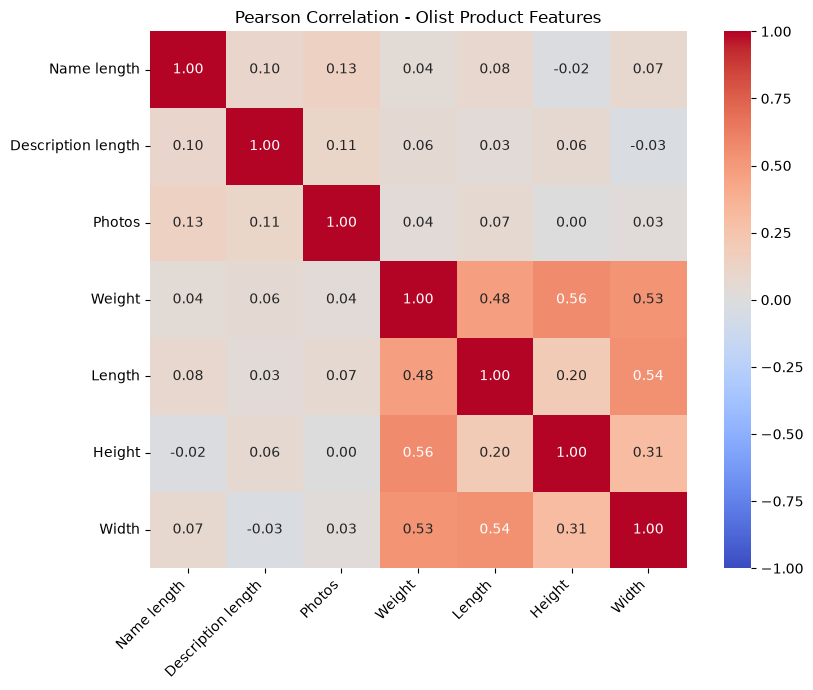

In [34]:
%pip install matplotlib seaborn

import matplotlib.pyplot as plt
import seaborn as sns

# Shorter labels for readability
short_names = {
    "product_name_lenght": "Name length",
    "product_description_lenght": "Description length",
    "product_photos_qty": "Photos",
    "product_weight_g": "Weight",
    "product_length_cm": "Length",
    "product_height_cm": "Height",
    "product_width_cm": "Width"
}

plot_corr = correlation_matrix.rename(
    index=short_names,
    columns=short_names
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    plot_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Pearson Correlation - Olist Product Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

| Correlation | Meaning |
|---|---|
| Near **+1** | Strong positive relationship: as one increases, the other tends to increase |
| Near **−1** | Strong negative relationship: as one increases, the other tends to decrease |
| Near **0** | Weak or no **linear** relationship |

Figure ... Correlation matrix of 7 numerical features in the cleaned Olist Products dataset.

By Pearson correlation calculation methods among 7 numerical features in the cleaned Olist Products dataset, we have found that the strongest correlation pair is Weight - Height with r = 0.5626, indicating a moderate positive linear relationship of the taller products tend to be heavier. In addition, there are also other strong positive relationship, such as Length - Width (r = 0.5417), Weight - Width (r = 0.5268), and Weight - Length (r = 0.4762). In contrast, features like name length, description length and photos show weak linear relationships with physical features. When applying in PCA later, correlated physical features share some information that PCA may capture their common variation in fewer components.

### **10. Summarize the main findings**

*How do data cleaning, integration, and transformation affect
the quality and reliability of the analysis?*

| Aspect | Result | Effect |
|---|---|---|
| Data Cleaning | Four zero-weight values were treated as missing. A total of 615 rows (1.87%) were removed, leaving 32,336 products with complete numerical features. | Removing incomplete records and invalid weight measurements improves PCA input quality. However, removing rows may introduce bias if the missing data are not random. |
| Data Integration | English category names were added without changing the number of products. For 13 products without translations, the original category names were used as display labels. | English labels make tables and visualizations easier to interpret. Integration does not change the seven numerical features used for PCA. |
| Data Transformation | Z-score standardization gives each numerical feature a mean of approximately 0 and a standard deviation of approximately 1. | Prevents larger measurement scales from dominating PCA. |
| Main Findings | Weight–Height has the highest absolute correlation (r = 0.5626), indicating a moderate positive linear relationship. Physical features are positively correlated, while text-length features and photo count have weak linear relationships with physical measurements. | Correlations among physical features suggest shared information that PCA may summarize in fewer components. The number of components to retain will be determined by the explained variance. |
| Remaining Limitations | Values flagged by IQR were retained because there was insufficient evidence that they were incorrect. | PCA remains sensitive to outliers, and standardization does not eliminate their influence. |

## **II. Principle Component Analysis (PCA)**

*Apply PCA to the two selected datasets. What preprocessing steps are necessary before applying PCA? Explain how the principal components are computed and selected*

### **1. Preprocessing data**
*PCA is applied to the seven standardized numerical features. Product IDs and category labels are excluded from the PCA input.*

**Standardized data**

In [35]:
import numpy as np

print("PCA input shape:", X_scaled.shape)
print("Missing values:", X_scaled.isna().sum().sum())

assert np.isfinite(X_scaled.to_numpy()).all(), \
    "PCA input contains missing or infinite values."

display(pd.DataFrame({
    "mean": X_scaled.mean(),
    "std": X_scaled.std(ddof=0)
}).round(4))

PCA input shape: (32336, 7)
Missing values: 0


,mean,std
product_name_lenght,-0.0,1.0
product_description_lenght,0.0,1.0
product_photos_qty,0.0,1.0
product_weight_g,0.0,1.0
product_length_cm,-0.0,1.0
product_height_cm,0.0,1.0
product_width_cm,0.0,1.0


**Covariance matrix computation**

This is computed from the standardized data to examine how the numerical features vary together.

In [36]:
X_pca_centered = X_scaled - X_scaled.mean()

pca_covariance = X_pca_centered.cov()

print("Covariance matrix shape:", pca_covariance.shape)
display(pca_covariance.round(4))

Covariance matrix shape: (7, 7)


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
product_name_lenght,1.0000,0.0988,0.1343,0.0447,0.0806,-0.0165,0.0707
product_description_lenght,0.0988,1.0000,0.1087,0.0624,0.0348,0.0636,-0.0308
product_photos_qty,0.1343,0.1087,1.0000,0.0365,0.0674,0.0041,0.0264
product_weight_g,0.0447,0.0624,0.0365,1.0000,0.4762,0.5626,0.5268
product_length_cm,0.0806,0.0348,0.0674,0.4762,1.0000,0.2021,0.5417
product_height_cm,-0.0165,0.0636,0.0041,0.5626,0.2021,1.0000,0.3115
product_width_cm,0.0707,-0.0308,0.0264,0.5268,0.5417,0.3115,1.0000


**Compute eigenvalues and eigenvectors**

Eigenvectors define the principal component directions, while
eigenvalues represent the variance along those directions.
Components are sorted by eigenvalue in descending order.

In [37]:
eigenvalues, eigenvectors = np.linalg.eigh(pca_covariance.to_numpy())

# sort eigen values from largest to smallest
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

pc_names = [
    f"PC{i+1}" for i in range(len(eigenvalues))
]  
eigenvalue_table = pd.DataFrame({
    "Component": pc_names,
    "Eigenvalue": eigenvalues
})

eigenvector_table = pd.DataFrame(
    eigenvectors,
    index=X_pca_centered.columns,
    columns=pc_names
)

display(eigenvalue_table.round(4))
display(eigenvector_table.round(4))

,Component,Eigenvalue
0,PC1,2.3434
1,PC2,1.2201
2,PC3,0.9786
3,PC4,0.8658
4,PC5,0.7997
5,PC6,0.4408
6,PC7,0.3518


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
product_name_lenght,-0.0796,-0.5846,0.3817,0.5664,-0.4295,0.0280,0.0135
product_description_lenght,-0.0576,-0.5187,-0.6764,0.2524,0.4421,-0.1039,0.0135
product_photos_qty,-0.0632,-0.6012,0.1135,-0.7812,-0.1016,-0.0328,-0.0004
product_weight_g,-0.5572,0.0676,-0.1471,-0.0139,-0.1533,0.1412,-0.7872
product_length_cm,-0.4786,-0.0340,0.2995,0.0208,0.4772,0.6040,0.2950
product_height_cm,-0.4266,0.1291,-0.4532,-0.0617,-0.5589,0.0825,0.5224
product_width_cm,-0.5146,0.0738,0.2592,0.0269,0.2149,-0.7718,0.1413


### **2. Explained variance of each principal component**
Analyze the explained variance of each principal component. What is the difference between selecting principal components with the highest and lowest explained variance? Comment on their significance.

In [38]:
explained_variance_ratio = eigenvalues / eigenvalues.sum()

cummulative_variance_ratio = np.cumsum(explained_variance_ratio)

variance_table = pd.DataFrame({
    "Component": pc_names,
    "Eigenvalue": eigenvalues,
    "Explained variance (%)": explained_variance_ratio * 100,
    "Cumulative variance (%)": cummulative_variance_ratio * 100
})

display(variance_table.round(4))

,Component,Eigenvalue,Explained variance (%),Cumulative variance (%)
0,PC1,2.3434,33.4761,33.4761
1,PC2,1.2201,17.4288,50.9049
2,PC3,0.9786,13.9797,64.8846
3,PC4,0.8658,12.3678,77.2523
4,PC5,0.7997,11.4244,88.6767
5,PC6,0.4408,6.2972,94.9739
6,PC7,0.3518,5.0261,100.0000


**Note for Report:**

- PC1 has the highest explained variance (33.48%), while PC7 is the lowest (5.03%).
- For a fixed number of retained components, selecting the PCs with the highest explained variance preserves the greatest amount of total variance. For a 2D representation, PC1 and PC2 together retain 50.9%.
- In comparison, selecting the 2 PCs with the lowest explained variance PC6 and PC7 retain only 11.32%.
- If we discard later PCs, it can reduce dimensionality but loses the variation represented by those components. Low-variance PCs are not necessarily noise and may still contain useful info.
- Since PCA does not use category labels, higher explained variance does not necessarily imply better category separation.

### **3. The number of selected principal components**

In [39]:
for threshold in [0.80, 0.90]:
    k = np.searchsorted(cummulative_variance_ratio, threshold) + 1

    print(f"Components needed for {threshold:.0%} variance: {k}")

Components needed for 80% variance: 5
Components needed for 90% variance: 6


In [40]:
n_features = X_scaled.shape[1]
k_values = np.arange(1, n_features + 1)

component_comparison = pd.DataFrame({
    "Number of PCs": k_values,
    "Retained variance (%)": cummulative_variance_ratio * 100,
    "Discarded variance (%)": (1 - cummulative_variance_ratio) * 100,
    "Dimensions removed": n_features - k_values
})

display(component_comparison.round(2))

,Number of PCs,Retained variance (%),Discarded variance (%),Dimensions removed
0,1,33.48,66.52,6
1,2,50.90,49.10,5
2,3,64.88,35.12,4
3,4,77.25,22.75,3
4,5,88.68,11.32,2
5,6,94.97,5.03,1
6,7,100.00,0.00,0


### **4. Visualize the data distributions in 2D using the first two principal components**

In [41]:
# Select the first two principal component directions
W_2 = eigenvectors[:, :2]

# Project the standardized, centered data onto PC1 and PC2
X_pca_2d = pd.DataFrame(
    X_pca_centered.to_numpy() @ W_2,
    columns=["PC1", "PC2"],
    index=X_pca_centered.index
)

print("Projected data shape:", X_pca_2d.shape)
display(X_pca_2d.head())

Projected data shape: (32336, 2)


,PC1,PC2
0,1.449557,1.166106
1,0.417484,1.043456
2,1.347756,0.845523
3,0.928208,1.927769
4,1.011899,0.263386


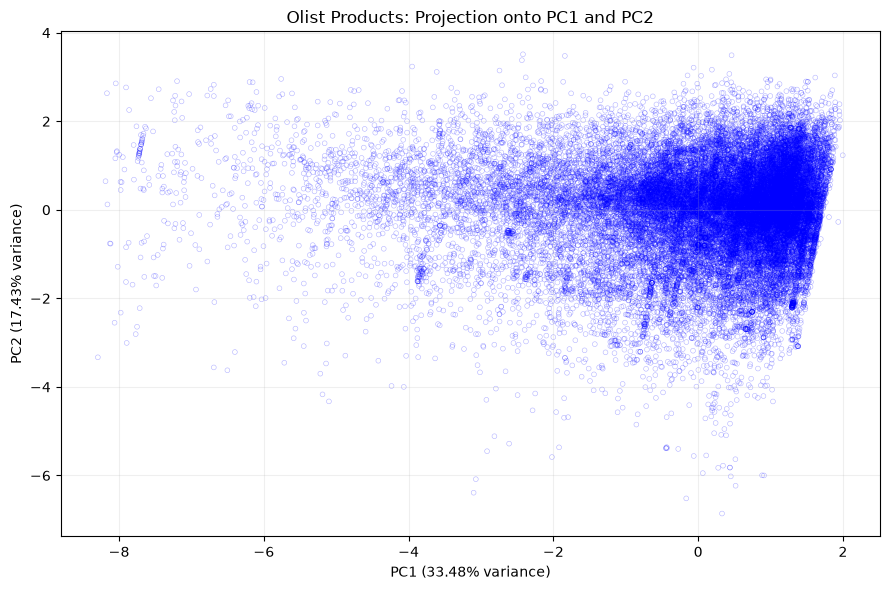

In [42]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca_2d["PC1"],
    X_pca_2d["PC2"],
    s=12,
    facecolors="none",       # Hollow circles
    edgecolors="blue",
    linewidths=0.4,
    alpha=0.3
)

plt.xlabel(f"PC1 ({explained_variance_ratio[0]:.2%} variance)")
plt.ylabel(f"PC2 ({explained_variance_ratio[1]:.2%} variance)")
plt.title("Olist Products: Projection onto PC1 and PC2")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Number of categories: 73
Missing labels: 0


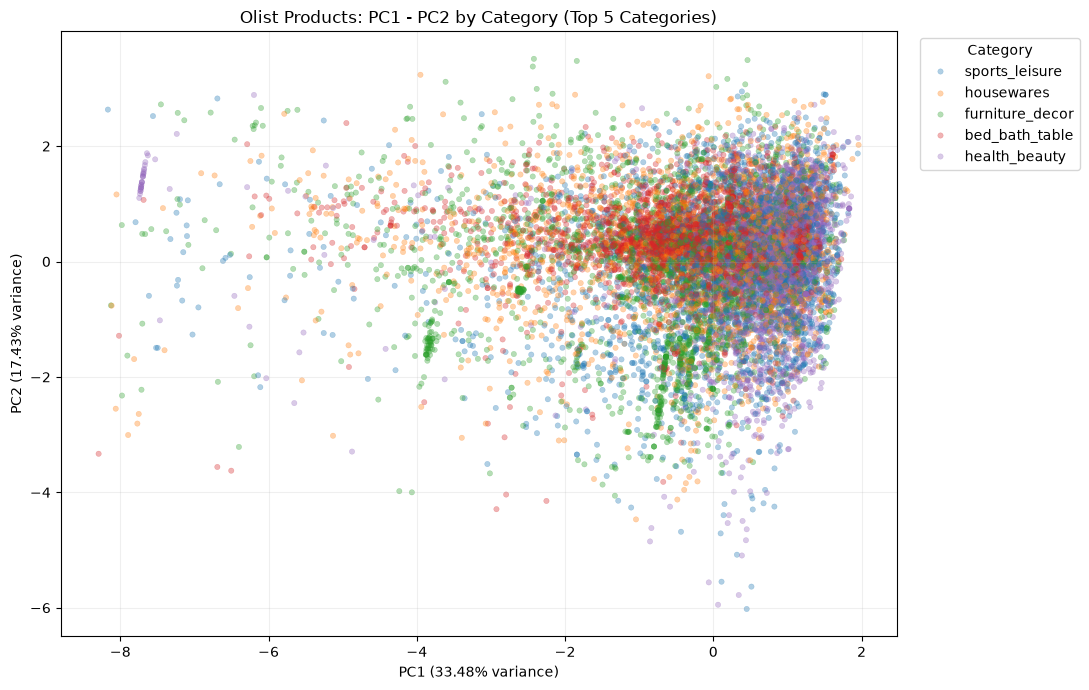

In [45]:
pca_plot = X_pca_2d.copy()

# Match labels to products using the existing row index
pca_plot["Category"] = products_integrated.loc[
    pca_plot.index, "category_display"
]

print("Number of categories:", pca_plot["Category"].nunique())
print("Missing labels:", pca_plot["Category"].isna().sum())

top_categories = (
    pca_plot["Category"]
    .value_counts()
    .head(5)
    .index
)

plot_top5 = pca_plot[
    pca_plot["Category"].isin(top_categories)
]

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=plot_top5,
    x="PC1",
    y="PC2",
    hue="Category",
    palette="tab10",
    s=15,
    alpha=0.35,
    edgecolor=None
)

plt.xlabel(f"PC1 ({explained_variance_ratio[0]:.2%} variance)")
plt.ylabel(f"PC2 ({explained_variance_ratio[1]:.2%} variance)")
plt.title("Olist Products: PC1 - PC2 by Category (Top 5 Categories)")
plt.legend(
    title="Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### **5. Original - PCA dataset comparison**

*Compare the original datasets with their PCA-transformed representations. Discuss the advantages and limitations of PCA in terms of information preservation, interpretability, and visualization.*

| | Original numerical data | PCA representation |
|---|---|---|
| Overall | Each product is described by 7 numerical features | Each product is described by ${k}$ principal component scores <br> Each PC is a linear combination of the 7 standardized features |
| Dimensions | 7  | ${k}$, with ${k}$ = 2 used for visualization |
| No. products | 32336 | 32336 (unchanged) |

**PCA pros and cons based on information preservation, interpretability, visualization**

| Aspect | Advantages | Limitations |
|---|---|---|
| **Information preservation** | PCA selects directions that retain the greatest variance for a given number of components. In this dataset, 5 PCs retain 88.68% of the total variance, while 6 PCs retain 94.97%. | Reducing dimensionality discards some variance. The first two PCs retain only 50.90%, leaving 49.10% unrepresented in the 2D projection. |
| **Interpretability** | Examining the component coefficients helps identify which original features contribute most to each PC. For example, PC1 mainly reflects variation in product weight and physical dimensions. | PCs combine multiple standardized features, making them less directly interpretable than original measurements such as weight in grams or height in centimetres. |
| **Visualization** | Projecting onto PC1 and PC2 allows the seven-dimensional data to be explored in a 2D scatter plot, showing concentrations, overlaps, and isolated points. | The plot captures only part of the total variance. The five displayed product categories overlap considerably, so they are not clearly separated in this projection. |